In [1]:
from pathlib import Path
import json
import sys

import pandas as pd
from IPython.display import Image, display

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

from lawankz.rk2_week1 import run_week1_analysis

RESULTS_DIR = PROJECT_ROOT / "results" / "rk2_week1"
summary = run_week1_analysis(
    PROJECT_ROOT / "results" / "weeks_1_4" / "processed_articles.jsonl",
    RESULTS_DIR,
)
summary["metrics"]

c:\Users\danil\Documents\AIU\Обработка языков\LawanKZ\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 31827.13it/s]


{'TF-IDF': {'same_document_mean_cosine': 0.0845,
  'different_document_mean_cosine': 0.034,
  'cosine_separation': 0.0505,
  'precision_at_2': 0.7,
  'hit_rate_at_2': 0.9333},
 'Transformer': {'same_document_mean_cosine': 0.9497,
  'different_document_mean_cosine': 0.9461,
  'cosine_separation': 0.0036,
  'precision_at_2': 0.0667,
  'hit_rate_at_2': 0.1333}}

## 2. Выбранные тексты

In [2]:
selected = pd.read_csv(RESULTS_DIR / "selected_texts.csv")
selected[[
    "label", "document_title", "article_number",
    "clean_word_count", "transformer_chunks"
]]

,label,document_title,article_number,clean_word_count,transformer_chunks
0,ПД-17,О персональных данных и их защите,17,81,2
1,ПД-3,О персональных данных и их защите,3,111,3
2,ПД-8,О персональных данных и их защите,8,201,4
3,КБ-59,О кибербезопасности,59,80,2
4,КБ-49,О кибербезопасности,49,132,2
5,КБ-60-2,О кибербезопасности,60-2,247,4
6,Связь-16-2,О связи,16-2,80,2
7,Связь-28-8,О связи,28-8,110,2
8,Связь-25,О связи,25,224,4
9,ИИ-21,Об искусственном интеллекте,21,83,2


## 3. TF-IDF и Transformer на одинаковых данных

In [3]:
metrics = pd.DataFrame(summary["metrics"]).T
metrics

,same_document_mean_cosine,different_document_mean_cosine,cosine_separation,precision_at_2,hit_rate_at_2
TF-IDF,0.0845,0.0340,0.0505,0.7000,0.9333
Transformer,0.9497,0.9461,0.0036,0.0667,0.1333


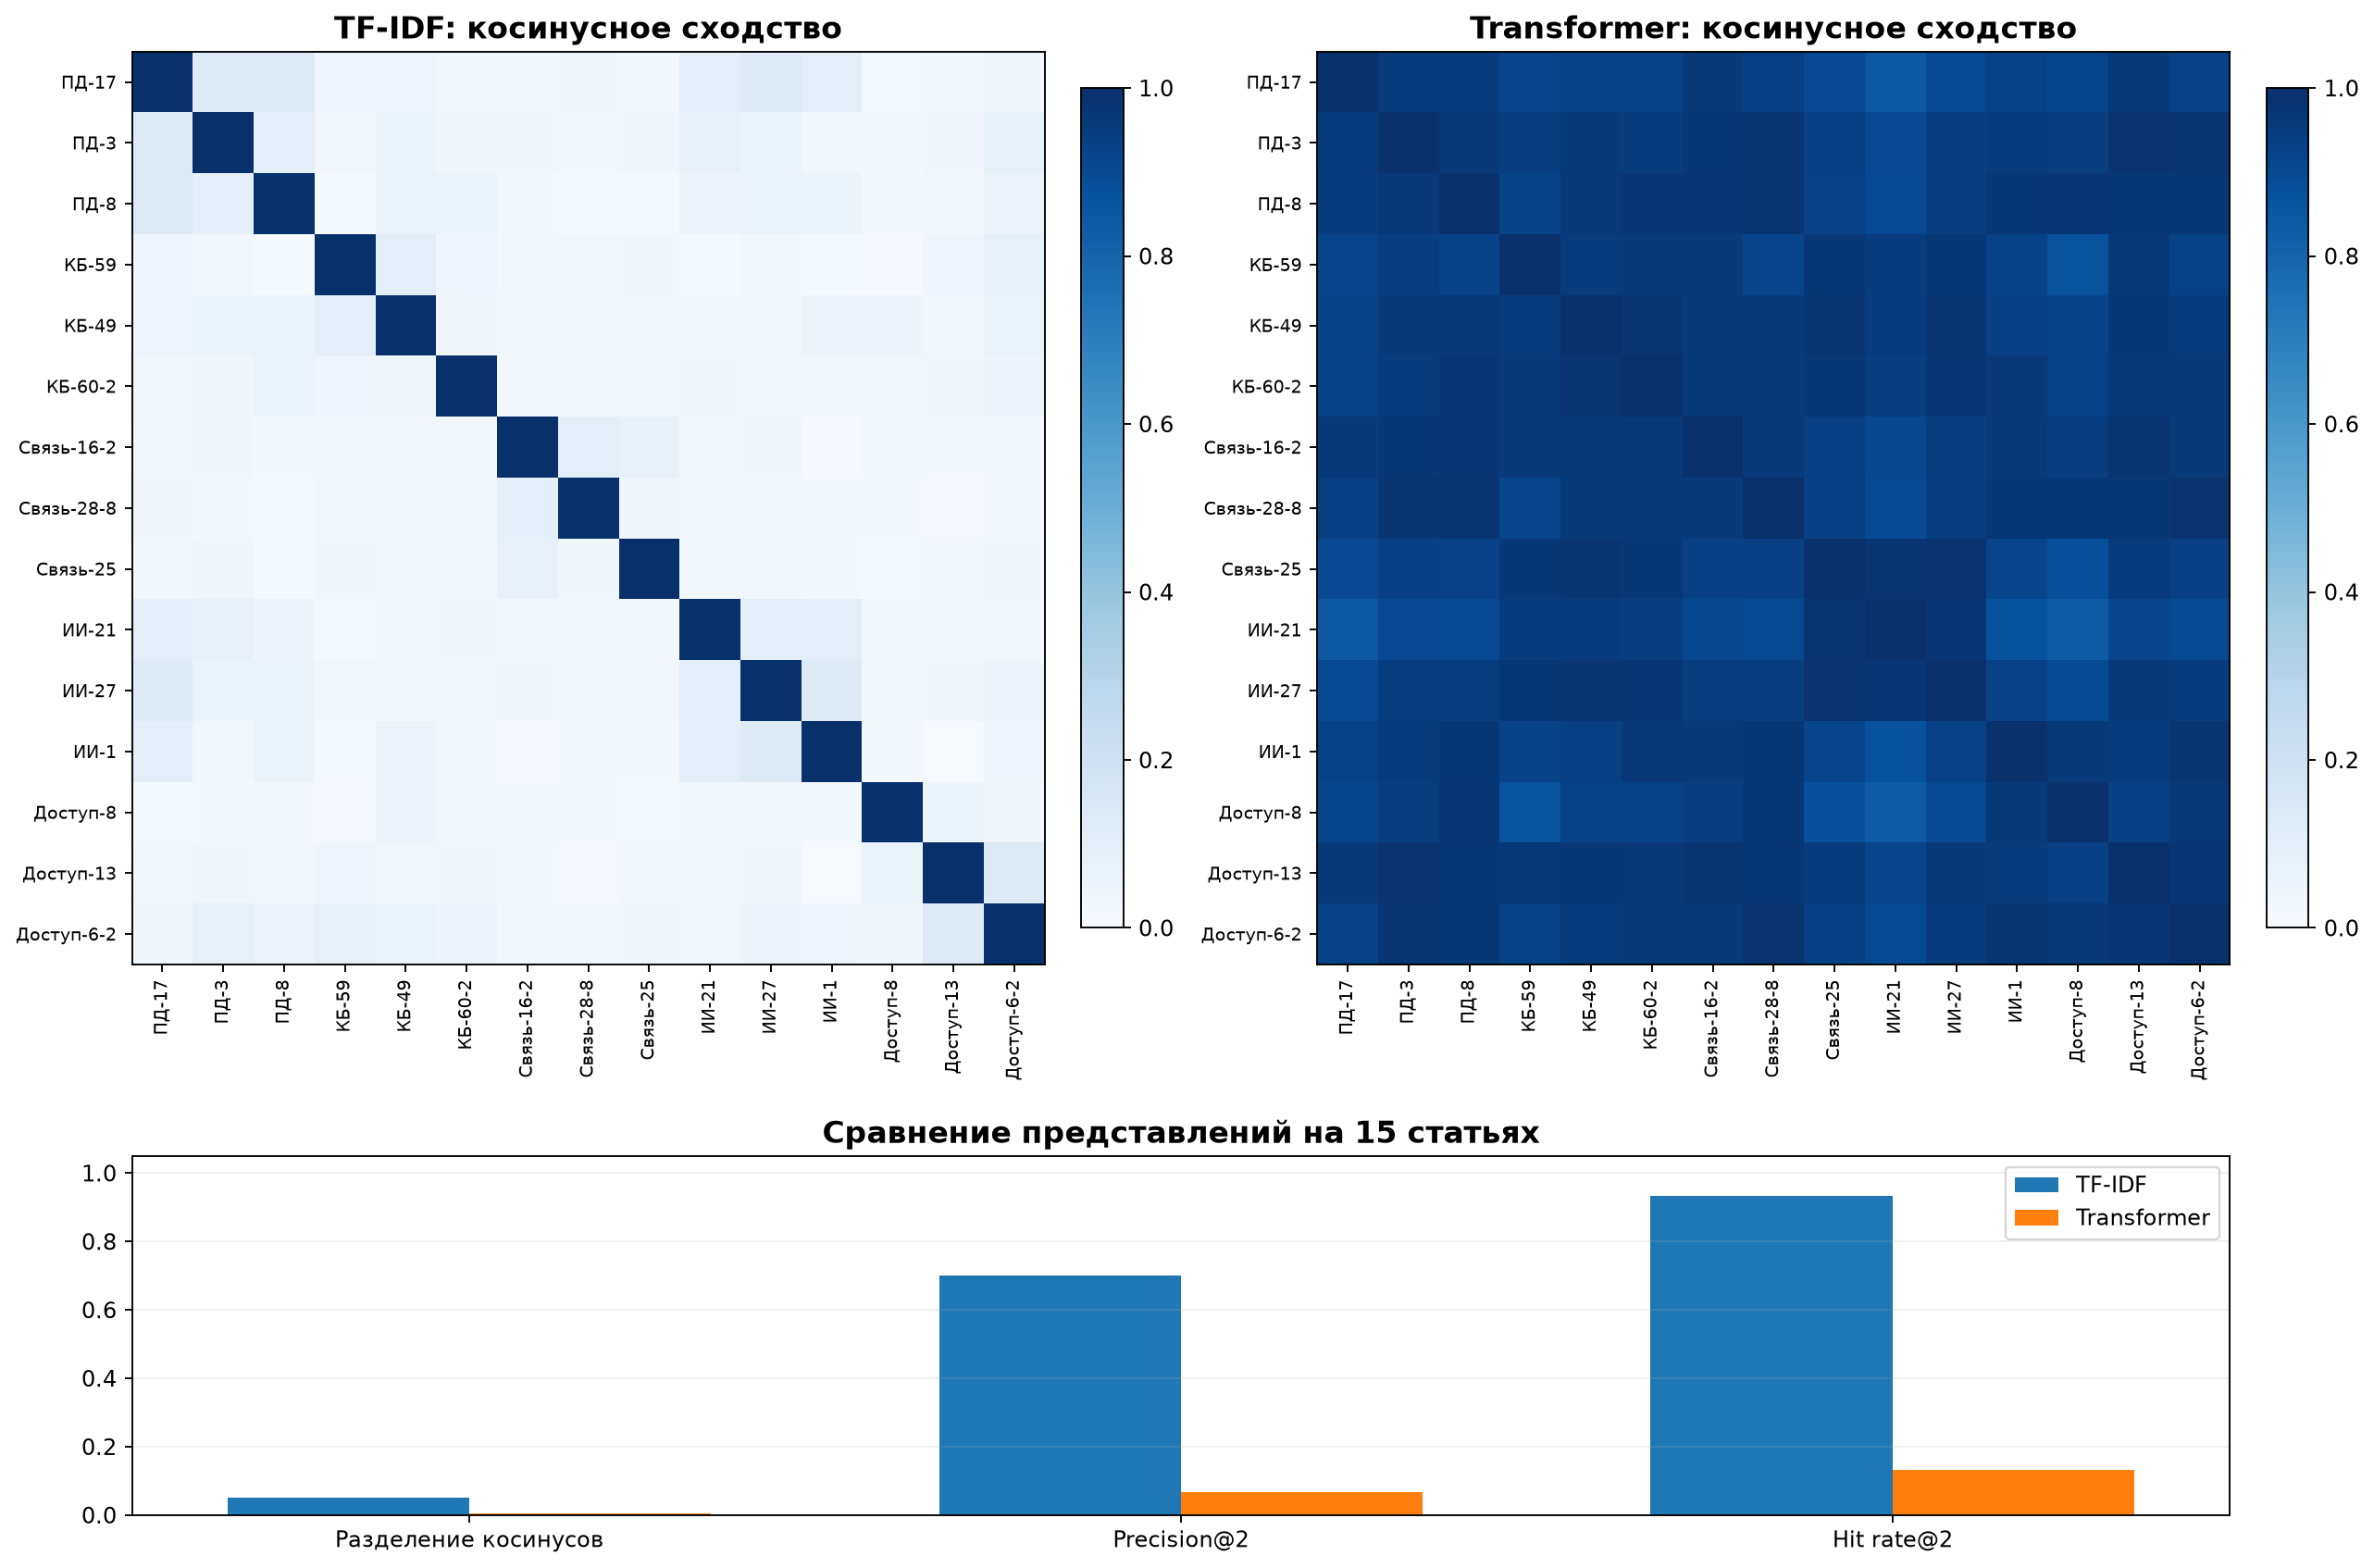

In [4]:
display(Image(filename=str(RESULTS_DIR / "tfidf_vs_transformer.png"), width=1000))

## 4. Контекстное значение слова «оператор»

In [5]:
context = json.loads((RESULTS_DIR / "context_analysis.json").read_text(encoding="utf-8"))
pd.DataFrame(context["sentences"])[["context", "sentence"]]

,context,sentence
0,персональные данные,"Сбор, обработка персональных данных осуществля..."
1,телекоммуникации,Мобильный оператор предоставляет абонентам усл...
2,кинопроизводство,Оператор снимает фильм на профессиональную кам...


In [6]:
pd.DataFrame(
    {
        "пара контекстов": [
            "персональные данные — телекоммуникации",
            "персональные данные — кинопроизводство",
            "телекоммуникации — кинопроизводство",
        ],
        "косинус скрытых векторов слова": [
            context["legal_vs_telecom_cosine"],
            context["legal_vs_cinema_cosine"],
            context["telecom_vs_cinema_cosine"],
        ],
    }
)

,пара контекстов,косинус скрытых векторов слова
0,персональные данные — телекоммуникации,0.6633
1,персональные данные — кинопроизводство,0.8516
2,телекоммуникации — кинопроизводство,0.8959
